# 03.5 · 因子库与因子体系

> 前面我们逐个研究了反转、小市值。真实的量化研究是**系统化地构建、评估、维护一个因子库**，并从中筛选、合成。
> 本节学会：**因子的分类体系、批量构造因子、用多持有期评估（区分快/慢因子）、因子相关性与去冗余**。

## 一、因子分类体系

量化因子通常按数据来源和性质分类：

| 大类 | 典型因子 | 说明 |
|---|---|---|
| **规模/风格** | 小市值、Beta、非线性规模 | Barra 风格因子，多为风险因子 |
| **价值/质量** | EP、BP、ROE、盈利成长 | 基本面，更新慢 |
| **量价-反转动量** | 短期反转、中期动量 | 行为偏差 |
| **量价-波动** | 波动率、特质波动、偏度 | 低波/低偏度异象 |
| **量价-流动性** | 换手率、成交额、Amihud | 流动性溢价 |
| **量价-形态** | 振幅、量比、量价背离 | 微观结构 |
| **另类数据** | 舆情、研报、卫星、供应链 | 前沿，alpha 衰减慢 |

> **风险因子 vs Alpha 因子**：风险因子（如市值、行业）解释收益、用来控风险；Alpha 因子提供超额收益。很多因子兼具两者属性。

## 二、批量构造因子（代码已沉淀在 factor_lab.library）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.library import build_factors
from factor_lab.preprocess import process_factor
from factor_lab.evaluate import ic_series
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
facs = build_factors(close, F['$volume'].unstack('instrument'),
                     F['$mkt_cap_ard'].unstack('instrument'),
                     F['$pe_ttm'].unstack('instrument'),
                     F['$pb_lf'].unstack('instrument'))
print('共构造因子:', len(facs))
for k in facs: print('  -', k)

[7924:MainThread](2026-10-29 19:55:49,945) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[7924:MainThread](2026-10-29 19:55:51,448) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[7924:MainThread](2026-10-29 19:55:51,449) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


共构造因子: 13
  - SMB 小市值
  - EP 盈利收益率
  - BP 账面市值比
  - REV5 短期反转
  - REV20 中期反转
  - MOM120 长期动量
  - 低波20
  - 低波60
  - 低换手20
  - 低成交额20
  - 低振幅20
  - 负偏度60
  - 低量比


## 三、统一评估：多持有期 IC（区分快/慢因子）

不同因子的预测力在不同持有期显现：
- **快因子**（如短期反转）：次日 IC 相对明显，衰减快；
- **慢因子**（如小市值、价值）：次日 IC 几乎为 0，但长持有期 IC 显著、稳定。

所以评估因子要**同时看多个持有期**，不能只看次日。下面对每个因子计算 1 日和 20 日 IC/IR。

In [2]:
def eval_factor(f, close):
    fp = process_factor(f)
    out = {}
    for k in [1, 20]:
        fwd = close.shift(-k)/close - 1
        ic = ic_series(fp, fwd)
        out['%d日IC' % k] = ic.mean()
        out['%d日IR' % k] = ic.mean()/ic.std()
    return pd.Series(out)

table = pd.DataFrame({name: eval_factor(f, close) for name, f in facs.items()}).T
table = table.sort_values('20日IR', ascending=False)
print(table.round(4))

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


... (11 outputs left out)

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


               1日IC    1日IR   20日IC   20日IR
SMB 小市值      0.0015  0.0078  0.0483  0.2475
低成交额20       0.0030  0.0186  0.0321  0.2017
负偏度60        0.0101  0.0774  0.0250  0.1879
REV20 中期反转   0.0133  0.0601  0.0200  0.1024
EP 盈利收益率     0.0173  0.0705  0.0168  0.0663
低波60         0.0237  0.0829  0.0171  0.0590
BP 账面市值比     0.0175  0.0680  0.0145  0.0523
低波20         0.0223  0.0845  0.0120  0.0449
REV5 短期反转    0.0233  0.1148  0.0063  0.0333
低量比          0.0143  0.1019 -0.0001 -0.0008
低振幅20        0.0168  0.0694 -0.0018 -0.0074
低换手20        0.0029  0.0186 -0.0027 -0.0172
MOM120 长期动量 -0.0003 -0.0013 -0.0088 -0.0386


**解读：**
- 小市值：1日 IC 几乎为 0（0.0015），但 20 日 IC 0.048、IR 0.25——典型**慢因子**；
- 短期反转：1日 IC 相对高（0.023），但 20 日反而不显著——**快因子**，适合高频调仓；
- 这解释了为什么小市值"次日 IC 接近 0 却能年化 32%"：微小优势持续累积。

### 直观对比：小市值 vs 短期反转的 IC 衰减曲线

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


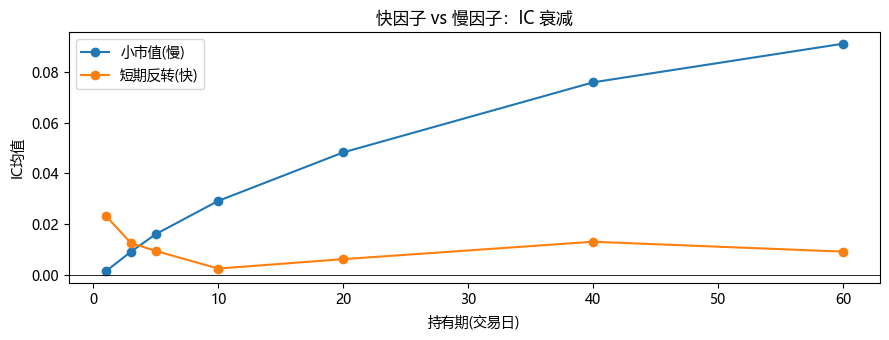

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for name, f in [('小市值(慢)', facs['SMB 小市值']),
                ('短期反转(快)', facs['REV5 短期反转'])]:
    fp = process_factor(f); xs, ys = [], []
    for k in [1, 3, 5, 10, 20, 40, 60]:
        ic = ic_series(fp, close.shift(-k)/close - 1)
        xs.append(k); ys.append(ic.mean())
    ax.plot(xs, ys, marker='o', label=name)
ax.axhline(0, color='black', lw=.6); ax.legend()
ax.set_xlabel('持有期(交易日)'); ax.set_ylabel('IC均值'); ax.set_title('快因子 vs 慢因子：IC 衰减')
plt.tight_layout(); plt.show()

## 四、因子相关性与去冗余

因子之间往往高度相关（如低波20与低波60），同时持有等于重复下注。要计算因子相关性，**剔除冗余因子**。

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\gucao\.conda\envs\qlib\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: Runtime

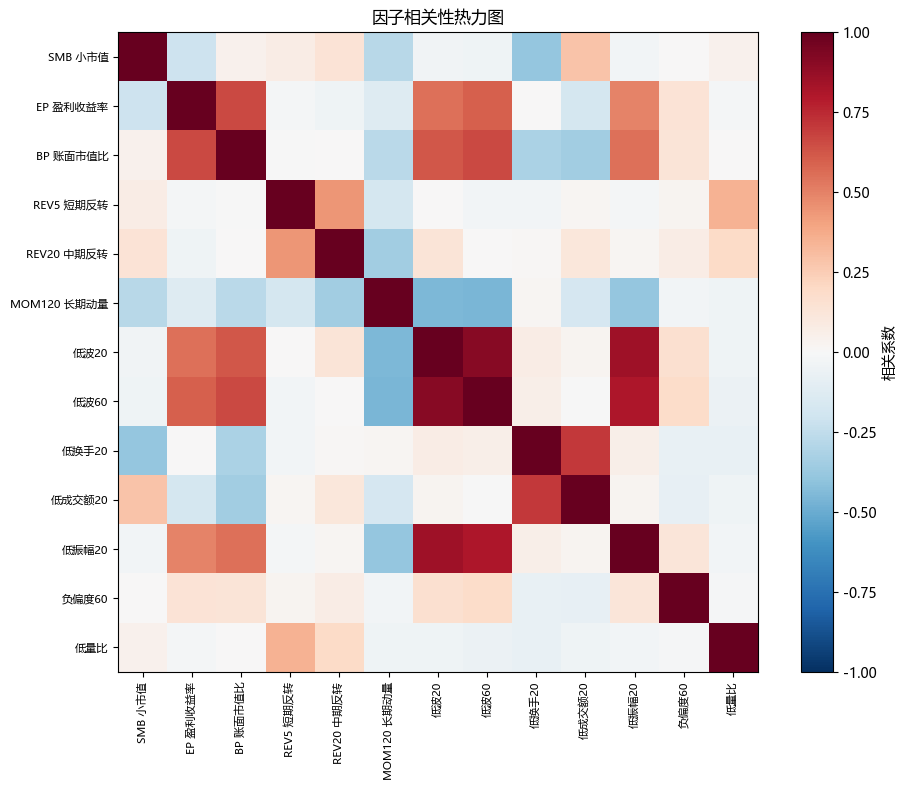

高相关因子对(|corr|>0.8):
   ('低波20', '低波60', np.float64(0.91))
   ('低振幅20', '低波20', np.float64(0.85))
   ('低振幅20', '低波60', np.float64(0.81))


In [4]:
# 取近一年因子值，计算相关性
pan = pd.DataFrame({k: process_factor(v).iloc[-250:].stack() for k, v in facs.items()})
corr = pan.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
plt.colorbar(label='相关系数')
plt.xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
plt.yticks(range(len(corr)), corr.columns, fontsize=8)
plt.title('因子相关性热力图'); plt.tight_layout(); plt.show()

# 找出高相关因子对
hi = [(i, j, round(corr.loc[i, j], 2)) for i in corr for j in corr
      if i < j and abs(corr.loc[i, j]) > 0.8]
print('高相关因子对(|corr|>0.8):')
for p in hi: print('  ', p)

## 五、去冗余与因子合成

处理高相关因子的方法：
1. **聚类后每组保留一个**（保留 IR 最高的）；如低波20/低波60/低振幅高度相关，只留一个；
2. **正交化**：用施密特正交或回归取残差，让因子两两不相关；
3. **因子合成**：把多个弱因子合成一个更强的信号——
   - 等权合成、IC/IR 加权合成（简单稳健）；
   - 机器学习合成（LightGBM、神经网络，模块 4 重点）。

> 单因子的 alpha 往往有限，**真正的超额收益来自多因子的有效合成**。

## 六、小结与面试要点

- 因子体系：规模/风格、价值/质量、反转动量、波动、流动性、形态、另类；区分风险因子与 alpha 因子。
- **快因子（反转）次日 IC 高、衰减快；慢因子（小市值）长持有期 IC 显著、靠持续累积**。
- 因子必须看**相关性、去冗余**；高相关因子只留一个或正交化。
- 多因子合成是提升 alpha 的关键（模块 4）。

**面试高频：**
- 你了解哪些大类因子？分别的收益来源？（答：规模=风险补偿，反转=行为偏差，流动性=微观结构）
- 风险因子和 alpha 因子的区别？（答：风险因子解释收益、用于控风险，alpha 因子提供超额）
- 两个因子高度相关怎么办？（答：保留 IR 高的，或回归正交化）
- 小市值因子次日 IC 很低，为什么长期收益高？（答：慢因子，微小优势持续累积，长持有期 IC 显著）

## 动手练习
1. 从因子库中选出 3 个低相关因子，做等权合成，看合成因子的 IC；
2. 用聚类（如层次聚类）对因子分组；
3. 思考：为什么另类数据因子的 alpha 衰减更慢？

---
下一节 **03.6 因子挖掘进阶：遗传规划 gplearn、强化学习 AlphaGen、深度学习/LLM 因子**。